In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import seaborn as sns
import scipy.integrate as sci_int

In [54]:
def drdt_i(r, theta):
    dr = r*(1-r**2) +mu*r*np.cos(theta)
    return dr
    
def dthetadt_i(r, theta):
    dtheta = theta*0+1
    return dtheta

def dxdt(dt, x):
    r = x[0]
    theta = x[1]
    dr = drdt_i(r, theta)
    dtheta = dthetadt_i(r, theta)
    return(np.array([dr, dtheta]))

In [17]:
colours = sns.color_palette('deep')

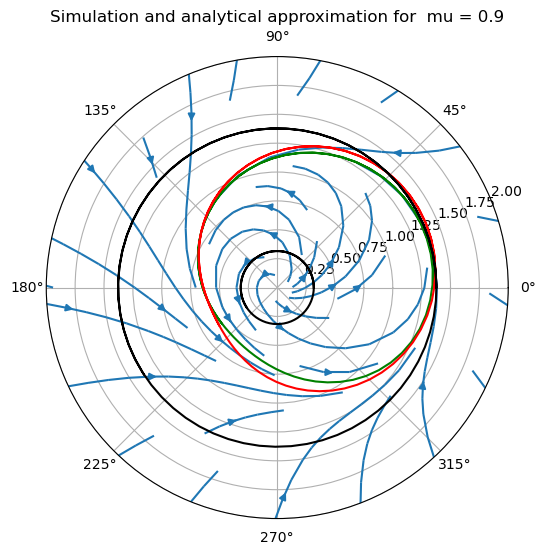

In [103]:
r_i = np.linspace(0., 3, 50)
theta_i = np.linspace(-np.pi, np.pi, 60)

theta_s, r_s = np.meshgrid(theta_i, r_i)

dr_i = drdt_i(r_s, theta_s)
dtheta_i = dthetadt_i(r_s, theta_s)

fig = plt.figure(figsize=(6,6))
myax = plt.axes(polar=True)

plt.streamplot(theta_i, r_i, dtheta_i, dr_i, density=0.6)

plt.ylim(0, 2)

    # Draw an initial condition to find the limit cycle
t0=0
tn=10
ni = 101
r = np.zeros(ni)
th = np.zeros(ni) 

qwe = sci_int.solve_ivp(dxdt, t_span=[t0,tn], y0=[1+mu*(1/5*np.sin(0)+2/5*np.cos(0)), 0], t_eval=np.linspace(t0,tn,ni))
r[:] = qwe.y[0]
th[:] = qwe.y[1]

    #Trajectory
qwe = plt.plot(th, r, 'g-')

    # Also plot the results of the analytic approximation
plt.plot(th,1+mu*(1/5*np.sin(th)+2/5*np.cos(th)), color = "r");
plt.title(f"Simulation and analytical approximation for  mu = {mu}");
plt.plot(th, th*0+np.sqrt(1+mu), "k")
plt.plot(th, th*0+np.sqrt(1-mu), "k");

In [56]:
def simulation(mu):

    r_i = np.linspace(0., 3, 50)
    theta_i = np.linspace(-np.pi, np.pi, 60)

    theta_s, r_s = np.meshgrid(theta_i, r_i)

    dr_i = drdt_i(r_s, theta_s)
    dtheta_i = dthetadt_i(r_s, theta_s)

    fig = plt.figure(figsize=(6,6))
    myax = plt.axes(polar=True)

    plt.ylim(0, 2)

    # Draw an initial condition to find the limit cycle
    t0=0
    tn=10
    ni = 101
    r = np.zeros(ni)
    th = np.zeros(ni) 

    qwe = sci_int.solve_ivp(dxdt, t_span=[t0,tn], y0=[1+mu*(1/5*np.sin(0)+2/5*np.cos(0)), 0], t_eval=np.linspace(t0,tn,ni))
    r[:] = qwe.y[0]
    th[:] = qwe.y[1]

    #Trajectory
    qwe = plt.plot(th, r, 'g-')

    # Also plot the results of the analytic approximation
    plt.plot(th,1+mu*(1/5*np.sin(th)+2/5*np.cos(th)), color = "r");
    plt.title(f"Simulation and analytical approximation for  mu = {mu}");

Simulate the system for various small mu:

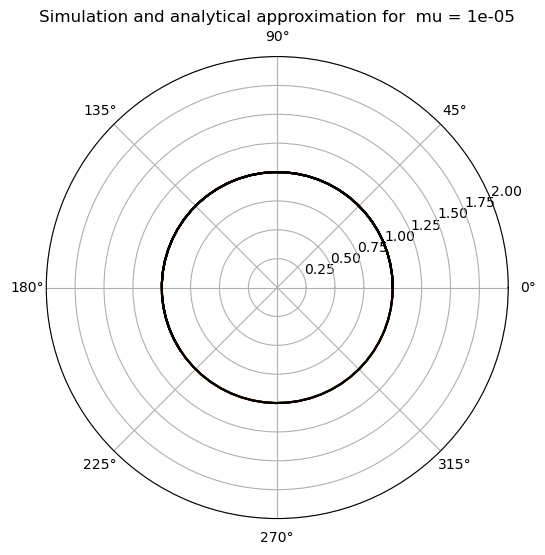

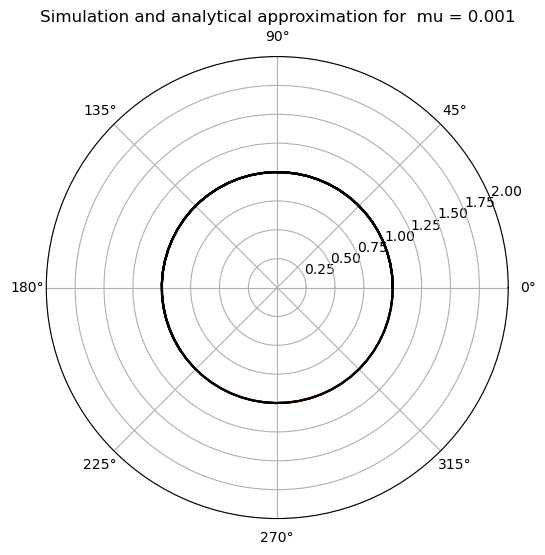

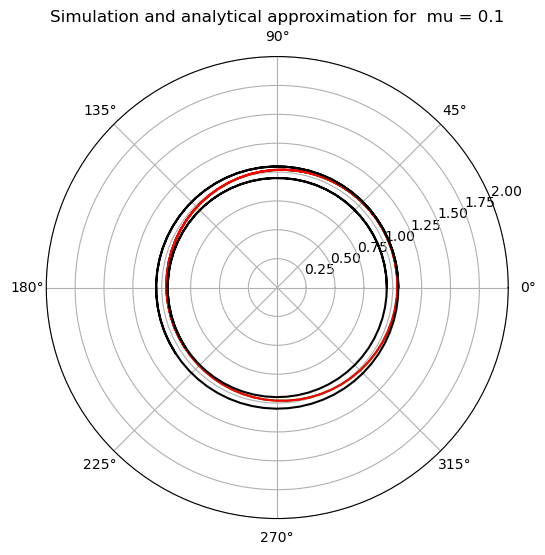

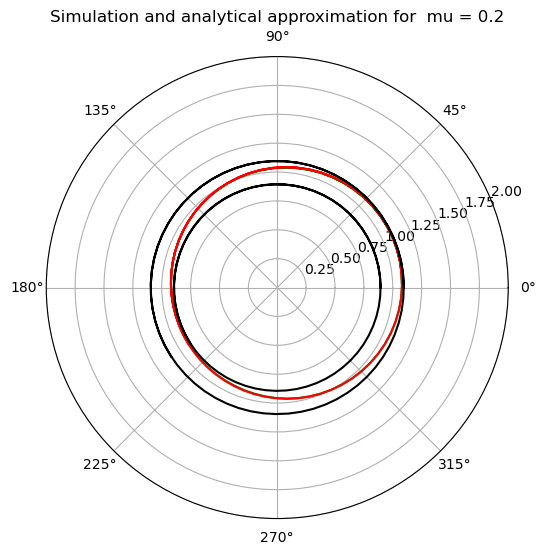

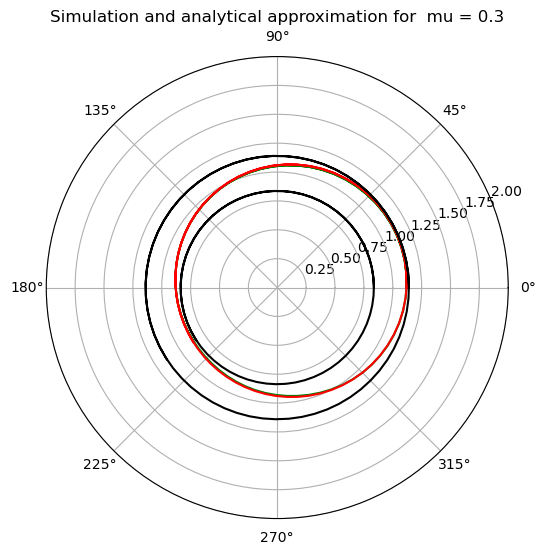

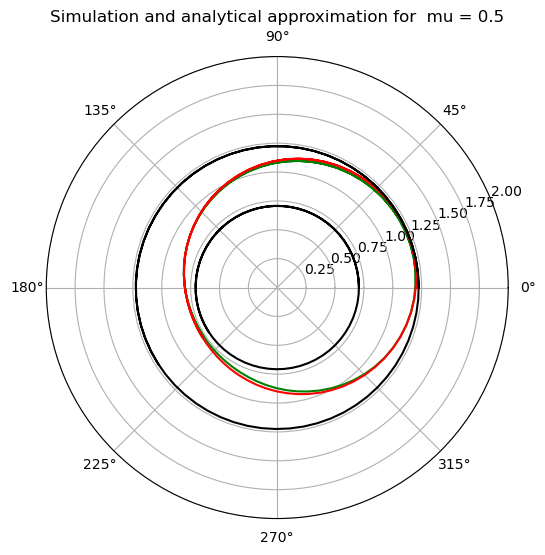

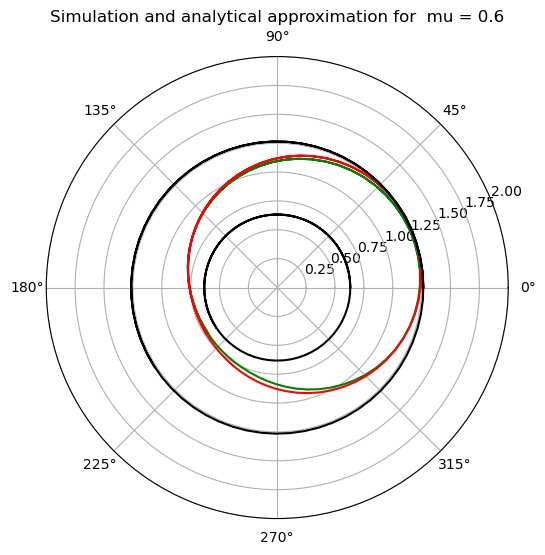

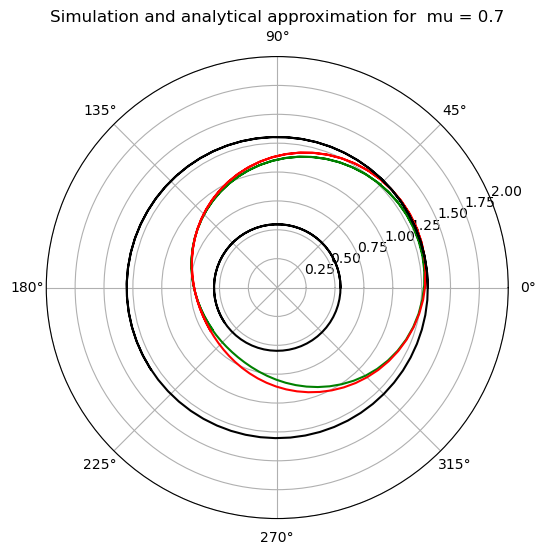

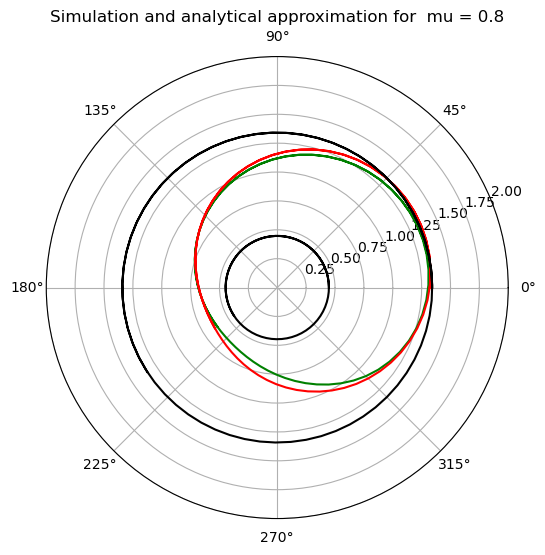

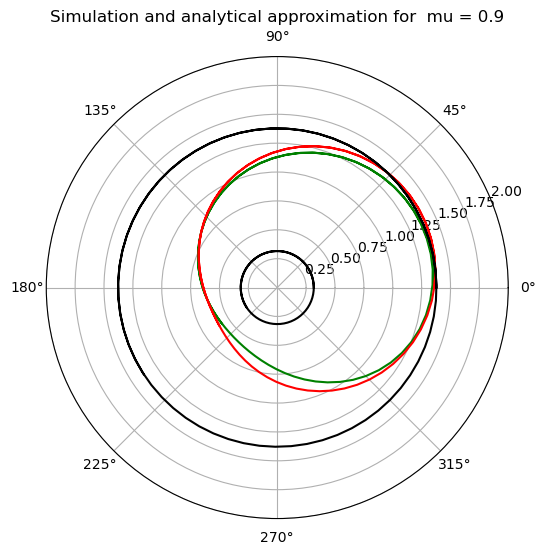

In [100]:
mu_list = [1e-5, 1e-3, 1e-1, 2e-1, 3e-1, 5e-1, 6e-1, 7e-1, 8e-1, 9e-1]
for mu in mu_list:
    simulation(mu)
    plt.plot(th, th*0+np.sqrt(1-mu), "k")
    plt.plot(th, th*0+np.sqrt(1+mu), "k")

It is clear that the simulation and analytical solution become closer together and more circular as mu gets smaller.

Find the maximum error for a set of small mu values, mu < 0.2

To do this, take the r values for qwe (the radial distances for the simulation) away from 1+mu*(1/5*np.sin(th)+2/5*np.cos(th)) ( the radial distances for the analytical approximation) 

In [134]:
def error_evaluation(mu):
    # Draw an initial condition to find the limit cycle
    t0=0
    tn=10
    ni = 101
    r = np.zeros(ni)
    th = np.zeros(ni) 

    qwe = sci_int.solve_ivp(dxdt, t_span=[t0,tn], y0=[1+mu*(1/5*np.sin(0)+2/5*np.cos(0)), 0], t_eval=np.linspace(t0,tn,ni))
    r[:] = qwe.y[0]
    th[:] = qwe.y[1]
    
    error = 1+mu*(1/5*np.sin(th)+2/5*np.cos(th)) - r
    # Return only the maximum error i.e. the maximum radial distance between green and red line for every specific theta value.
    return max(error)

The value returned from error_evaluation is the maximum error between simulation and analytic approximation

In [137]:
small_mu_list = [0.02, 0.04, 0.06, 0.08, 0.1, 0.12, 0.14, 0.16, 0.18, 0.2]
errors = []
for mu in small_mu_list:
    errors.append(error_evaluation(mu))

Plot the max error as a function of mu

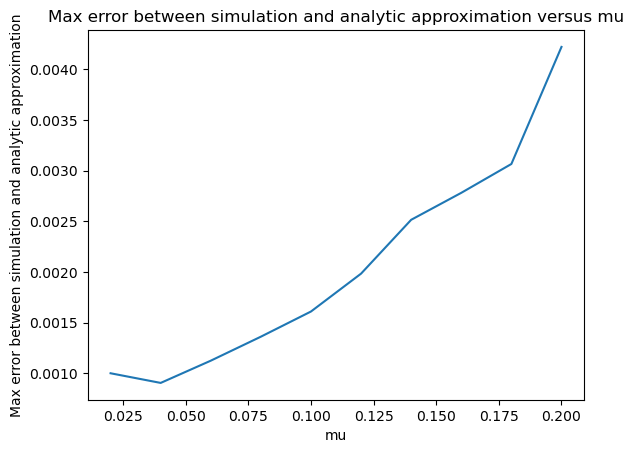

In [138]:
plt.plot(small_mu_list, errors)
plt.title("Max error between simulation and analytic approximation versus mu")
plt.xlabel("mu")
plt.ylabel("Max error between simulation and analytic approximation");

Use a fitting curve to find if this is a quadratic relationship

In [139]:
from scipy.optimize import curve_fit
%matplotlib inline

In [140]:
# Defining equation of linear line of best fit 
def fitfunc(x, a, b, c):
    return a*x**2+b*x+c

In [141]:
pars1

array([-2.40285461e+01,  3.15035030e-01,  8.23249096e-04])

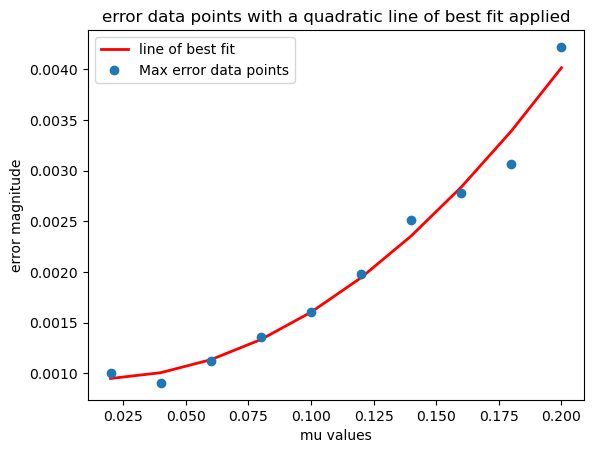

In [146]:
pars1, cov1 = curve_fit(fitfunc, small_mu_list, errors)

plt.plot(small_mu_list, fitfunc(np.array(small_mu_list), *pars1),
         linewidth = '2', label = "line of best fit", color = "r")
plt.plot(small_mu_list, errors, "o", label = "Max error data points")
plt.legend()
plt.title("error data points with a quadratic line of best fit applied")
plt.ylabel("error magnitude")
plt.xlabel("mu values");

There appears to be a quadratic dependence on the maximum error as a function of mu.

In [144]:
pars1

array([ 0.08866365, -0.00246319,  0.00096246])

The final formula is Error(mu) = 0.08866365*mu^2 - 0.00246319*mu + 0.00096246